# **Regularization & Optimization**

In [ ]:
import tensorflow as tf

from matplotlib import pyplot as plt

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train, y_train), (X_test, y_test) = fashion_mnist

X_train = X_train / 255
X_test = X_test / 255

print("Image Size: ", X_train[0].shape)
print("Size of tarining set", len(X_train))
print("Size of testing set", len(X_test))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Image Size:  (28, 28)
Size of tarining set 60000
Size of testing set 10000


In [ ]:
# Flatten images (28x28 → 784)
X_train = X_train.reshape(-1, 28*28)
X_test = X_test.reshape(-1, 28*28)

In [ ]:
# Baseline Models

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

_epochs = 30
_batch_size = 32
_lr = 0.001


# Build small model
model_small = Sequential([
    Input(shape=(X_train.shape[1],)),      # Explicit input layer
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Build medium model
model_medium = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

# Build large model
model_large = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(4096, activation='relu'),
    Dense(2048, activation='relu'),
    Dense(1024, activation='relu'),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

model_small.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

model_medium.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

model_large.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

In [ ]:
model_small.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def plot_histories(histories, names, measure,
                   xlim_max=40,ylim_min=0,ylim_max=0):

    measure_to_pretty = {'sparse_categorical_crossentropy': 'loss',
                         'accuracy': 'accuracy'}
    nb_histories = len(histories)
    fig = plt.figure(figsize=plt.figaspect(0.05 * nb_histories))

    for i in range(nb_histories):
        ax = fig.add_subplot(1, nb_histories, i + 1)
        ax.plot(histories[i].history[f'val_{measure}'],
                label=f'Test {measure_to_pretty[measure]}, {names[i]}')
        plt.xlabel('Epoch')
        plt.ylabel(measure)
        plt.legend()
        plt.xlim(0,xlim_max)
        plt.ylim(ylim_min,ylim_max)
        #plt.gca().set_aspect('equal', adjustable='box')
        plt.draw()


    plt.show()

In [ ]:
history_small = model_small.fit(X_train, y_train,
                                validation_data=(X_test, y_test),
                                epochs=40, verbose=1)
history_medium = model_medium.fit(X_train, y_train,
                                  validation_data=(X_test, y_test),
                                  epochs=40, verbose=1)
history_large = model_large.fit(X_train, y_train,
                                validation_data=(X_test, y_test),
                                epochs=40, verbose=1)

Epoch 1/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8271 - loss: 0.4954 - sparse_categorical_crossentropy: 0.4954 - val_accuracy: 0.8433 - val_loss: 0.4388 - val_sparse_categorical_crossentropy: 0.4388
Epoch 2/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8636 - loss: 0.3760 - sparse_categorical_crossentropy: 0.3760 - val_accuracy: 0.8501 - val_loss: 0.4062 - val_sparse_categorical_crossentropy: 0.4062
Epoch 3/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8771 - loss: 0.3371 - sparse_categorical_crossentropy: 0.3371 - val_accuracy: 0.8714 - val_loss: 0.3568 - val_sparse_categorical_crossentropy: 0.3568
Epoch 4/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8844 - loss: 0.3126 - sparse_categorical_crossentropy: 0.3126 - val_accuracy: 0.8676 - val_loss: 0.3642 - val_sparse_categorical_crossentropy: 0.3642
Epoch 5/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8922 - loss: 0.2951 - sparse_categorical_crossentropy: 0.295

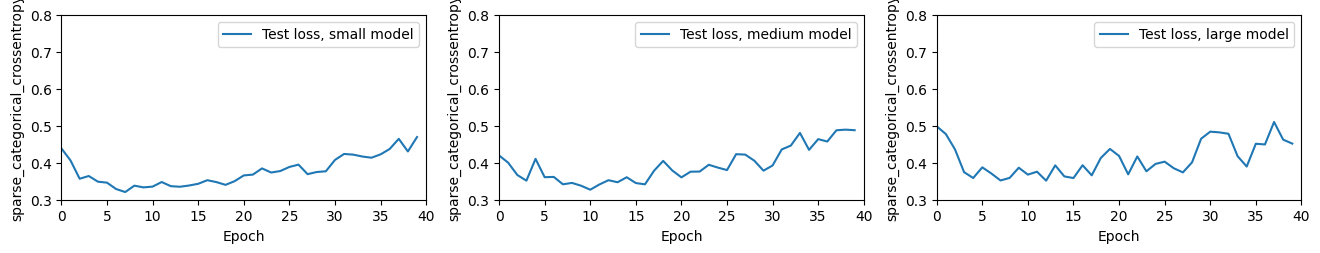

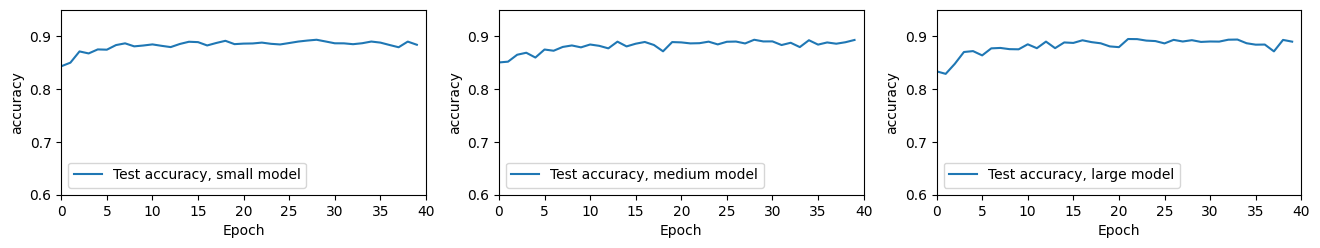

In [ ]:
plot_histories(histories=[history_small, history_medium, history_large],
               names=['small model', 'medium model', 'large model'],
               measure='sparse_categorical_crossentropy',
               xlim_max=40,ylim_min=0.3,ylim_max=0.8)
plot_histories(histories=[history_small, history_medium, history_large],
               names=['small model', 'medium model', 'large model'],
               measure='accuracy', xlim_max=40,ylim_min=0.6,ylim_max=0.95)

Epoch 1/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8258 - loss: 0.4935 - sparse_categorical_crossentropy: 0.4935 - val_accuracy: 0.8473 - val_loss: 0.4167 - val_sparse_categorical_crossentropy: 0.4167
Epoch 2/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8654 - loss: 0.3738 - sparse_categorical_crossentropy: 0.3738 - val_accuracy: 0.8489 - val_loss: 0.4154 - val_sparse_categorical_crossentropy: 0.4154
Epoch 3/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8765 - loss: 0.3373 - sparse_categorical_crossentropy: 0.3373 - val_accuracy: 0.8635 - val_loss: 0.3714 - val_sparse_categorical_crossentropy: 0.3714
Epoch 4/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8860 - loss: 0.3142 - sparse_categorical_crossentropy: 0.3142 - val_accuracy: 0.8711 - val_loss: 0.3548 - val_sparse_categorical_crossentropy: 0.3548
Epoch 5/40
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8927 - loss: 0.2935 - sparse_categorical_crossentropy: 0.293

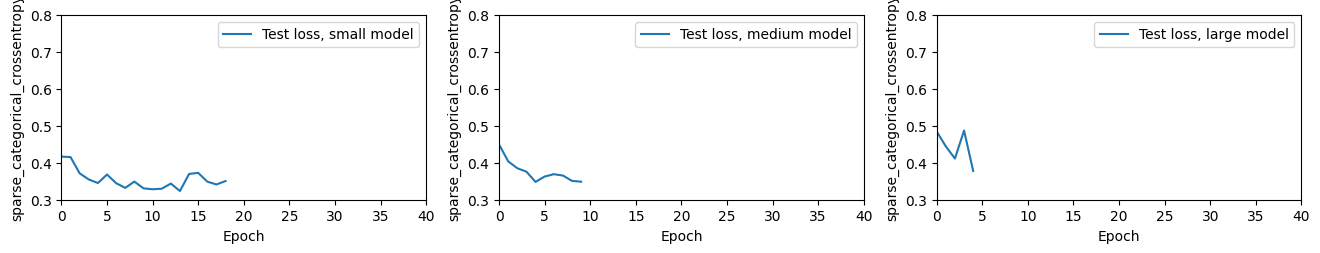

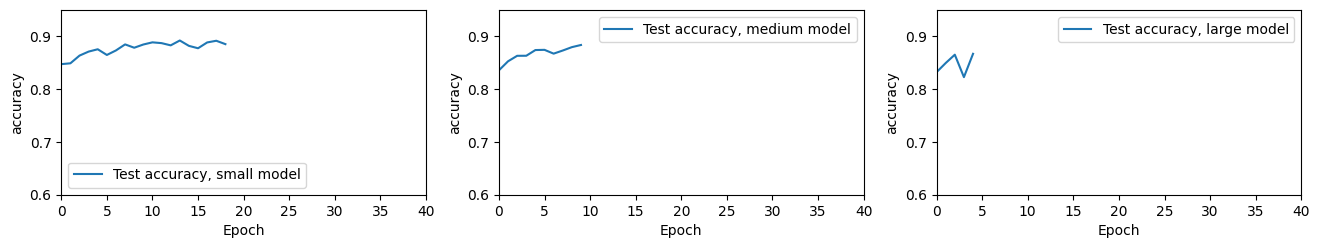

In [ ]:
# Add early stopping

from tensorflow.keras.callbacks import EarlyStopping

early_stopping1 = EarlyStopping(
    min_delta=0.001, # minimium amount of change
    patience=5, # how many epochs to wait before stopping
    restore_best_weights=True,
)

early_stopping2 = EarlyStopping(
    min_delta=0.001, # minimium amount of change
    patience=5, # how many epochs to wait before stopping
    restore_best_weights=True,
)


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

_epochs = 40
_batch_size = 32
_lr = 0.001


# Build small model
model_small = Sequential([
    Input(shape=(X_train.shape[1],)),      # Explicit input layer
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Build medium model
model_medium = Sequential([
    Input(shape=(X_train.shape[1],)),      # Explicit input layer
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

# Build large model
model_large = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(4096, activation='relu'),
    Dense(2048, activation='relu'),
    Dense(1024, activation='relu'),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])



model_small.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

model_medium.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

model_large.compile(optimizer=Adam(learning_rate=_lr),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_crossentropy', 'accuracy'])

history_small = model_small.fit(X_train, y_train,
                                validation_data=(X_test, y_test),
                                callbacks=[early_stopping1],
                                epochs=40, verbose=1)
history_medium = model_medium.fit(X_train, y_train,
                                  validation_data=(X_test, y_test),
                                  callbacks=[early_stopping2],
                                  epochs=40, verbose=1)

history_large = model_large.fit(X_train, y_train,
                                  validation_data=(X_test, y_test),
                                  callbacks=[early_stopping2],
                                  epochs=40, verbose=1)


plot_histories(histories=[history_small, history_medium, history_large],
               names=['small model', 'medium model', 'large model'],
               measure='sparse_categorical_crossentropy',
               xlim_max=40,ylim_min=0.3,ylim_max=0.8)
plot_histories(histories=[history_small, history_medium, history_large],
               names=['small model', 'medium model', 'large model'],
               measure='accuracy', xlim_max=40,ylim_min=0.6,ylim_max=0.95)

In [ ]:
# Add L1/L2 Norm
# Dense(4096, activation='relu', tf.keras.regularizers.l2(0.001)),

In [ ]:
# Add Dropout
# Dropout(0.2)

In [ ]:
# Add Batchnormalization
# BatchNormalization()